# 第3回 モデル定義と事前分布

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。
「🧪 実験」のセルだけは、数字を変えて何度か実行してみてください。

**この回のゴール**

1. ケーススタディ1と同じMMMを、PyMC-Marketing で組み立てる
2. 「事前分布」とは何かを、図で理解する
3. データを学習させる**前**に、モデルがおかしな予測をしないか確かめる（事前予測チェック）

この回ではまだ学習（推定）はしません。学習は第4回です。

**所要時間**：45〜60分。重い計算はなく、どのセルも30秒以内に終わります。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/03-model-priors>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


ライブラリを読み込みます。初回は30秒ほどかかります。

- 自分のPC（Windows）では `g++ not available` という WARNING が1行出ることがあります。計算を速くする部品が入っていないという知らせで、この教材では別の方法で速くしているので、無視してかまいません。
- `warnings.filterwarnings("ignore")` は、動作に影響しない注意書きを非表示にします。

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from pymc_extras.prior import Prior
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.multidimensional import MMM

SEED = 42                  # 乱数の種。固定すると毎回同じ結果になる
FAST = {"mode": "NUMBA"}   # 計算を速くする設定（5章で使う）


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


> **メモ**：`MMM` は `pymc_marketing.mmm.multidimensional` から読み込みます。
> 以前の `from pymc_marketing.mmm import MMM` は次のバージョン（0.20）で廃止されるためです。
> ケーススタディ1の本家ノートブックも、こちらの新しい `MMM` を使っています。

## 1. データの準備

第1回で見た「公開学習用データ」を読み込み、モデルに使う列だけを取り出します。

| 役割 | 列 | 数 |
|---|---|---|
| 目的変数 | `sales` | 1 |
| 広告チャネル | `mdsp_` で始まる列のうち7つ | 7 |
| コントロール変数 | `hldy_` で始まる列（祝日フラグ） | 22 |

第1回の小課題のとおり、`auddig`・`viddig`・`sem` の3チャネルは使いません。

In [3]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

# 列名 → 日本語のチャネル名
channel_names = {
    "mdsp_dm": "DM",
    "mdsp_inst": "折込",
    "mdsp_nsp": "新聞",
    "mdsp_audtr": "ラジオ",
    "mdsp_vidtr": "TV",
    "mdsp_so": "ソーシャル",
    "mdsp_on": "ディスプレイ",
}
channel_columns = list(channel_names.values())
control_columns = [c for c in raw_df.columns if c.startswith("hldy_")]

date_column = "wk_strt_dt"
target_column = "sales"

data_df = raw_df[[date_column, target_column, *channel_names.keys(), *control_columns]]
data_df = data_df.rename(columns=channel_names)

print("行数:", len(data_df))
print("チャネル:", channel_columns)
print("コントロール変数の数:", len(control_columns))
data_df.head(3)

行数: 209
チャネル: ['DM', '折込', '新聞', 'ラジオ', 'TV', 'ソーシャル', 'ディスプレイ']
コントロール変数の数: 22


,wk_strt_dt,sales,DM,折込,新聞,ラジオ,TV,ソーシャル,ディスプレイ,hldy_Black Friday,...,hldy_Memorial Day,hldy_Mother's Day,hldy_NYE,hldy_New Year's Day,hldy_Pre Thanksgiving,hldy_Presidents Day,hldy_Prime Day,hldy_Thanksgiving,hldy_Valentine's Day,hldy_Veterans Day
0,2014-08-03,72051457.64,678410.26,129759.66,507635.16,254134.14,216725.59,0.0,61364.75,0,...,0,0,0,0,0,0,0,0,0,0
1,2014-08-10,78794770.54,661097.71,70355.33,625719.37,106602.98,108919.26,0.0,132643.90,0,...,0,0,0,0,0,0,0,0,0,0
2,2014-08-17,70071185.56,1874338.43,107720.37,277532.61,59011.42,74032.19,0.0,76741.27,0,...,0,0,0,0,0,0,0,0,0,0


### 学習用とテスト用に分ける

2018年2月1日までを**学習用（train）**、それより後を**テスト用（test）**にします。
テスト用のデータはモデルに見せず、第6回で「未来を当てられるか」の検証に使います。

- `X`：モデルへの入力（日付・広告費・祝日）
- `y`：当てたいもの（売上）

In [4]:
split_date = pd.to_datetime("2018-02-01")

train_df = data_df[data_df[date_column] <= split_date]
test_df = data_df[data_df[date_column] > split_date]

X_train = train_df.drop(columns=target_column)
y_train = train_df[target_column]
X_test = test_df.drop(columns=target_column)
y_test = test_df[target_column]

print(f"学習用: {len(train_df)} 週 / テスト用: {len(test_df)} 週")

学習用: 183 週 / テスト用: 26 週


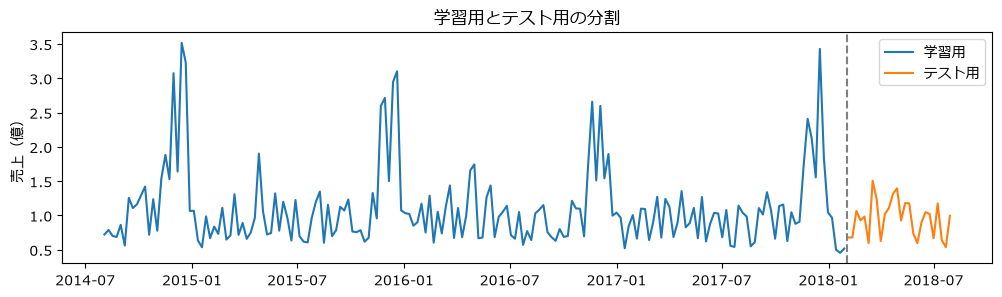

In [5]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(train_df[date_column], train_df[target_column] / 1e8, label="学習用")
ax.plot(test_df[date_column], test_df[target_column] / 1e8, label="テスト用")
ax.axvline(split_date, color="gray", linestyle="--")
ax.set_ylabel("売上（億）")
ax.set_title("学習用とテスト用の分割")
ax.legend();

## 2. これから作るモデルの全体像

MMMは、毎週の売上を次の足し算で説明します。

$$
\text{売上}_t \;=\; \underbrace{b}_{\text{ベース}}
\;+\; \underbrace{\sum_{c=1}^{7} \beta_c \cdot S\big(A(x_{c,t};\,\alpha_c);\,\lambda_c\big)}_{\text{広告の貢献}}
\;+\; \underbrace{\sum_{k=1}^{22} \gamma_k \, z_{k,t}}_{\text{祝日の影響}}
\;+\; \underbrace{\text{季節}_t}_{\text{1年周期の波}}
\;+\; \underbrace{\varepsilon_t}_{\text{誤差}}
$$

- $x_{c,t}$：チャネル $c$ の $t$ 週の広告費　／　$z_{k,t}$：祝日 $k$ のフラグ
- $A$ は adstock、$S$ は saturation。第2回で自作した2つの関数です。

**モデルがデータから推定する数字（パラメータ）**

| 記号 | 意味 | 個数 |
|---|---|---|
| $b$ | ベース売上（広告も祝日もない週の売上） | 1 |
| $\alpha_c$ | adstock：翌週に残る割合 | 7 |
| $\lambda_c$ | saturation：頭打ちの早さ | 7 |
| $\beta_c$ | チャネルの効果の大きさ | 7 |
| $\gamma_k$ | 祝日ごとの影響 | 22 |
| 季節の係数 | 1年周期の波の大きさ | 10 |
| $\sigma$ | 誤差の大きさ | 1 |

合計 **55個**（4章で実際に数えます）。一方、学習用データは **183週**しかありません。
データだけで55個の数字を決めるのは不安定なので、
「だいたいこのくらいのはず」という見込みを先に与えます。これが**事前分布**です。

## 3. 事前分布とは

ベイズ推定では、パラメータを「1つの数字」ではなく「ありそうな値の広がり（分布）」として扱います。

- **事前分布**：データを見る前の見込み
- **事後分布**：データを見た後の結論（第4回で求めます）

データが十分にあれば、事後分布はデータに引っぱられます。データが少ないと、事前分布の影響が強く残ります。

ケーススタディ1が使う事前分布を、図で見てみましょう。

### 3-1. adstock の α：Beta(1, 3)

α は「翌週に残る割合」で、0〜1の値です。0〜1の範囲に収まる Beta 分布を使います。

平均: 0.25
αが0.5を超える確率: 0.125


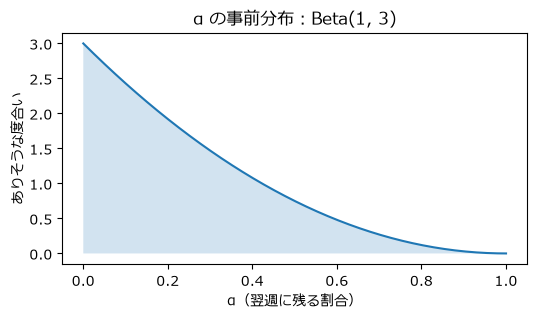

In [6]:
x = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, stats.beta(1, 3).pdf(x))
ax.fill_between(x, stats.beta(1, 3).pdf(x), alpha=0.2)
ax.set_xlabel("α（翌週に残る割合）")
ax.set_ylabel("ありそうな度合い")
ax.set_title("α の事前分布：Beta(1, 3)")

print("平均:", stats.beta(1, 3).mean())
print("αが0.5を超える確率:", round(1 - stats.beta(1, 3).cdf(0.5), 3))

**読み方**：小さい値ほどありそうで、平均は0.25。「広告効果はあまり長く残らないだろう」という控えめな見込みです。
ただし 0.5 を超える可能性も約12%残してあり、データが強く示せば大きな α にもなれます。

### 3-2. saturation の λ：Gamma(3, 1)

λ は「頭打ちの早さ」で、正の値です。正の値だけをとる Gamma 分布を使います。

平均: 3.0
94%が入る範囲: [0.66 6.98]


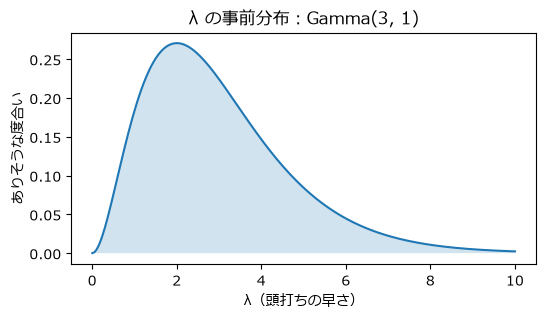

In [7]:
x = np.linspace(0, 10, 200)
lam_prior = stats.gamma(a=3, scale=1)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, lam_prior.pdf(x))
ax.fill_between(x, lam_prior.pdf(x), alpha=0.2)
ax.set_xlabel("λ（頭打ちの早さ）")
ax.set_ylabel("ありそうな度合い")
ax.set_title("λ の事前分布：Gamma(3, 1)")

print("平均:", lam_prior.mean())
print("94%が入る範囲:", lam_prior.ppf([0.03, 0.97]).round(2))

**読み方**：平均は3で、ほとんどが 0.6〜7 の範囲です。
第2回で見たとおり、λ=1 ならゆるやかな頭打ち、λ=4 以上ならかなり早い頭打ちなので、どちらもありうる幅広い見込みです。

### 3-3. 効果の大きさ β：HalfNormal(σ = 費用シェア)

ここがケーススタディ1の工夫です。

β は「そのチャネルが売上をどれだけ押し上げるか」で、広告が売上を減らすことはないと考えて**0以上**に限定します。
0以上だけの HalfNormal 分布を使い、その広がり σ を**チャネルごとの費用シェア**にします。

まず費用シェアを計算します（学習用データだけを使います）。

DM        0.450
折込        0.048
新聞        0.163
ラジオ       0.068
TV        0.100
ソーシャル     0.052
ディスプレイ    0.119
dtype: float64

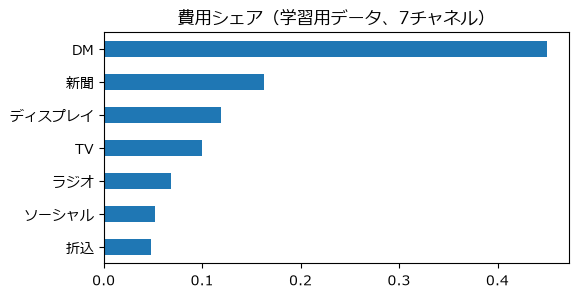

In [8]:
spend_share = X_train[channel_columns].sum() / X_train[channel_columns].sum().sum()
spend_share.sort_values().plot.barh(figsize=(6, 3), title="費用シェア（学習用データ、7チャネル）")
spend_share.round(3)

> 第1回の割合（DM 32.3% など）と数字が違うのは、分母が違うためです。
> 今回は sem などを除いた7チャネルの合計で割っているので、DM は約45%になります。

この費用シェアを σ にした HalfNormal を、3つのチャネルで比べます。

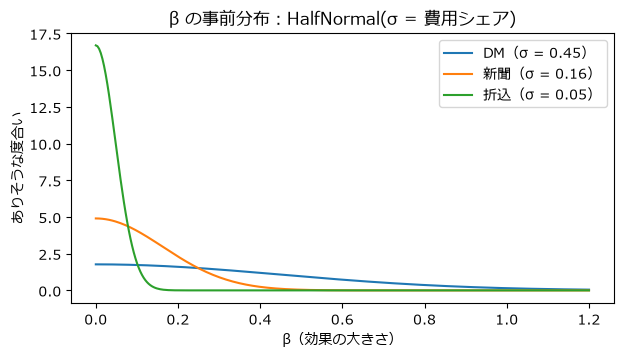

In [9]:
x = np.linspace(0, 1.2, 300)
fig, ax = plt.subplots(figsize=(7, 3.5))
for ch in ["DM", "新聞", "折込"]:
    sigma = spend_share[ch]
    ax.plot(x, stats.halfnorm(scale=sigma).pdf(x), label=f"{ch}（σ = {sigma:.2f}）")
ax.set_xlabel("β（効果の大きさ）")
ax.set_ylabel("ありそうな度合い")
ax.set_title("β の事前分布：HalfNormal(σ = 費用シェア)")
ax.legend();

**読み方**

- 費用の少ない「折込」は、0の近くに細くとがっています → 「効果は小さいはず」と強めに決めている
- 費用の多い「DM」は、右に長く広がっています → 「大きい効果もありうる」と幅を持たせている

**なぜ費用シェアを使うのか**（本家ノートブックの説明の要約）

- 会社は効くと思うチャネルに多く使っているはずなので、費用シェアを効果の目安にする
- 費用が小さいチャネルは、データから効果を見分けにくい。事前分布を狭くして、極端な推定値が出るのを防ぐ
- あくまで「よい出発点」であり、正解ではない

**注意点**：これは「たくさん使っているチャネルほど効くはず」という仮定を置いています。
実際に効いていないチャネルに多く使っている会社では、この仮定が結果をゆがめるおそれがあります。
結果を人に説明するときは、この仮定を置いたことを必ず伝えます。

### 3-4. 残りの事前分布

| パラメータ | 事前分布 | 意味 |
|---|---|---|
| ベース $b$ | Normal(0.2, 0.05) | ベース売上は、最大売上の約20%（10〜30%の範囲） |
| 祝日 $\gamma_k$ | Normal(0, 1) | 祝日は売上を上げることも下げることもある |
| 季節の係数 | Laplace(0, 1) | 0付近にとがった分布。不要な波は小さく抑える |
| 誤差 $\sigma$ | HalfNormal(1) | 誤差の大きさ（正の値） |

**「0.2」とは何の20%か？** → PyMC-Marketing は、売上と広告費を自動で「最大値で割って」0〜1の大きさにそろえます（次の章で確かめます）。
だから 0.2 は「最大売上の20%」という意味です。本当にそのくらいか、データで確かめます。

最大売上: 3.52 億
0.2 にあたる売上: 0.7 億
売上が低いほうから25%目の週: 0.199


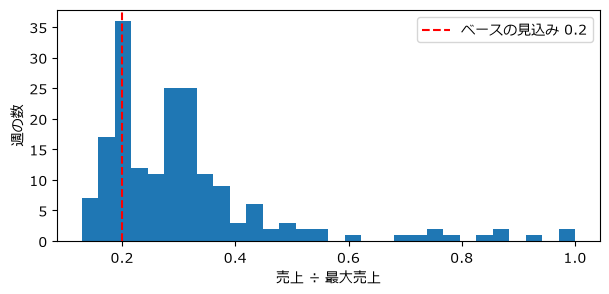

In [10]:
scaled_sales = y_train / y_train.max()

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(scaled_sales, bins=30)
ax.axvline(0.2, color="red", linestyle="--", label="ベースの見込み 0.2")
ax.set_xlabel("売上 ÷ 最大売上")
ax.set_ylabel("週の数")
ax.legend()

print("最大売上:", round(y_train.max() / 1e8, 2), "億")
print("0.2 にあたる売上:", round(0.2 * y_train.max() / 1e8, 2), "億")
print("売上が低いほうから25%目の週:", round(scaled_sales.quantile(0.25), 3))

**読み方**：0.2 は、売上が低い週（下から25%目あたり）の水準です。
「広告と祝日と季節の上乗せがない週の売上」の見込みとして、無理のない値だとわかります。

## 4. モデルを組み立てる

事前分布を `model_config` という辞書にまとめ、`MMM` に渡します。

- `Prior("分布の名前", パラメータ...)` で事前分布を1つ作ります。
- `dims="channel"` は「チャネルごとに1つずつ用意する」という意味です。
- α と λ はここに書いていません。書かなければ、3-1・3-2 で見た初期設定（Beta(1,3) と Gamma(3,1)）が使われます。

In [11]:
prior_sigma = spend_share[channel_columns].to_numpy()   # チャネルの順番をそろえて取り出す

model_config = {
    "intercept": Prior("Normal", mu=0.2, sigma=0.05),
    "saturation_beta": Prior("HalfNormal", sigma=prior_sigma, dims="channel"),
    "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
    "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
    "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)),
}

> `likelihood` の `TruncatedNormal(lower=0)` は「売上は0未満にならない」という条件つきの正規分布です。

次に `MMM` 本体です。第2回の2つの部品がそのまま出てきます。

- `GeometricAdstock(l_max=6)`：幾何減衰の adstock。6週前までを足す
- `LogisticSaturation()`：ロジスティック型の saturation
- `yearly_seasonality=5`：1年周期の波を、sin と cos それぞれ5つ（合計10個）の組み合わせで表す

In [12]:
mmm = MMM(
    model_config=model_config,
    date_column=date_column,
    target_column=target_column,
    channel_columns=channel_columns,
    control_columns=control_columns,
    adstock=GeometricAdstock(l_max=6),
    saturation=LogisticSaturation(),
    yearly_seasonality=5,
)

mmm.build_model(X_train, y_train)

# 貢献を「元の売上の単位」でも記録するように指定
mmm.add_original_scale_contribution_variable(
    var=[
        "channel_contribution",
        "control_contribution",
        "intercept_contribution",
        "yearly_seasonality_contribution",
        "y",
    ]
)

### モデルの中身を確認する

実際に設定された事前分布を一覧にします。書かなかった `adstock_alpha` と `saturation_lam` に初期設定が入っていることを確かめてください。

In [13]:
for name, prior in mmm.model_config.items():
    print(f"{name:16s} {prior}")

intercept        Prior("Normal", mu=0.2, sigma=0.05)
likelihood       Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1))
gamma_control    Prior("Normal", mu=0, sigma=1, dims="control")
gamma_fourier    Prior("Laplace", mu=0, b=1, dims="fourier_mode")
adstock_alpha    Prior("Beta", alpha=1, beta=3, dims="channel")
saturation_lam   Prior("Gamma", alpha=3, beta=1, dims="channel")
saturation_beta  Prior("HalfNormal", sigma=[0.44983506 0.04780756 0.16278453 0.06840006 0.10005879 0.05234825
 0.11876576], dims="channel")


In [14]:
# パラメータの個数を数える
n_params = {name.split("_log")[0]: value.size for name, value in mmm.model.initial_point().items()}
print(n_params)
print("合計:", sum(n_params.values()))

{'intercept_contribution': 1, 'adstock_alpha': 7, 'saturation_lam': 7, 'saturation_beta': 7, 'gamma_control': 22, 'gamma_fourier': 10, 'y_sigma': 1}
合計: 55


### 自動スケーリングの確認（第2回の宿題）

第2回で「費用をそのまま saturation に入れると全部 1.0 になる」ことを見ました。
PyMC-Marketing が内部で自動的にスケーリングしているかを確かめます。

In [15]:
print(mmm.scaling)
print()
print("売上を割っている数:", float(mmm.scalers["_target"]))
print("学習用データの最大売上:", y_train.max())
print()
check = pd.DataFrame({
    "モデルが割っている数": mmm.scalers["_channel"].to_series(),
    "学習用データの最大費用": X_train[channel_columns].max(),
})
check

target=VariableScaling(method='max', dims=()) channel=VariableScaling(method='max', dims=())

売上を割っている数: 351597976.78
学習用データの最大売上: 351597976.78



,モデルが割っている数,学習用データの最大費用
DM,2409895.71,2409895.71
折込,590148.11,590148.11
新聞,2198467.40,2198467.40
ラジオ,435614.54,435614.54
TV,1100083.38,1100083.38
ソーシャル,573355.55,573355.55
ディスプレイ,695750.18,695750.18


**結果**：`method='max'`、つまり売上もチャネルごとの広告費も、**学習用データの最大値で自動的に割られています**。
自分でスケーリングする必要はありません。そして事前分布の数字（ベース 0.2 など）は、すべてこの「0〜1にそろえた世界」での値です。

## 5. 事前予測チェック

ここがこの回の山場です。

**やること**：データをまだ学習させていない状態で、事前分布からパラメータを4,000組ランダムに引き、それぞれで売上を計算します。
つまり「事前の見込みだけで、モデルはどんな売上を想像するか」を見ます。

**何を確かめるか**

- 想像した売上の範囲が、実際の売上をおおっているか（狭すぎないか）
- マイナスの売上や、実際の100倍といった**ありえない値**が出ていないか（広すぎないか）

> `compile_kwargs=FAST` は計算を速くする指定です。g++ が無い環境（Windows など）では、これを付けないと1回に7〜10分かかります。
> 付けると初回は20秒ほど、2回目以降は数秒で終わります。

In [16]:
mmm.sample_prior_predictive(X_train, y_train, samples=4_000, random_seed=SEED, compile_kwargs=FAST)

prior = mmm.idata["prior"]
prior["y_original_scale"].shape   # (チェーン, サンプル数, 週の数)

Sampling: [adstock_alpha, gamma_control, gamma_fourier, intercept_contribution, saturation_beta, saturation_lam, y, y_sigma]


(1, 4000, 183)

4,000通りの「想像上の売上の推移」ができました。週ごとに、4,000個のうち真ん中の94%と50%が入る範囲を帯で描き、実際の売上と重ねます。

94%の範囲の上端（週の平均）: 24.1 億
94%の範囲の下端（週の平均）: 0.0 億


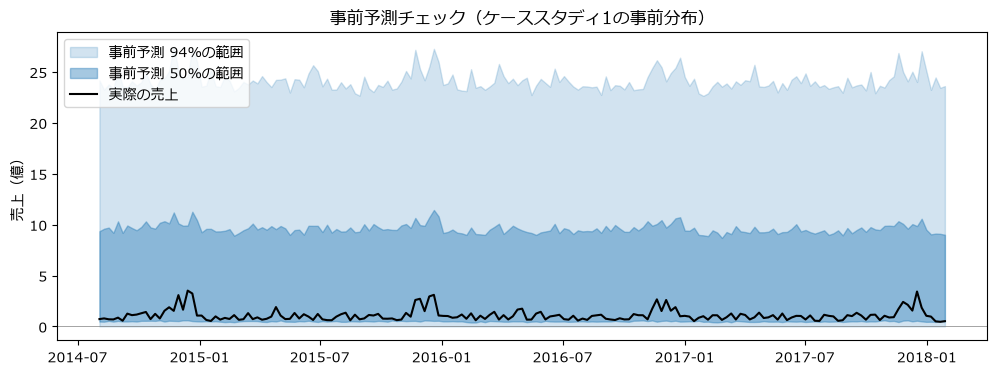

In [17]:
def plot_prior_predictive(model, title):
    y_prior = model.idata["prior"]["y_original_scale"] / 1e8
    q = y_prior.quantile([0.03, 0.25, 0.75, 0.97], dim=("chain", "draw"))
    dates = X_train[date_column]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.fill_between(dates, q.sel(quantile=0.03), q.sel(quantile=0.97), alpha=0.2, color="C0", label="事前予測 94%の範囲")
    ax.fill_between(dates, q.sel(quantile=0.25), q.sel(quantile=0.75), alpha=0.4, color="C0", label="事前予測 50%の範囲")
    ax.plot(dates, y_train / 1e8, color="black", label="実際の売上")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.set_ylabel("売上（億）")
    ax.set_title(title)
    ax.legend(loc="upper left")
    print("94%の範囲の上端（週の平均）:", round(float(q.sel(quantile=0.97).mean()), 1), "億")
    print("94%の範囲の下端（週の平均）:", round(float(q.sel(quantile=0.03).mean()), 1), "億")
    return ax

plot_prior_predictive(mmm, "事前予測チェック（ケーススタディ1の事前分布）");

**読み方**

- 黒い線（実際の売上）は、帯の中に収まっている → 事前分布は**狭すぎない**。合格
- マイナスの売上は出ていない（`TruncatedNormal(lower=0)` のおかげ）。合格
- ただし帯の上端は約24億で、実際の最大売上（約3.5億）の約7倍 → **かなり広い**
- 帯がほぼ平らで、12月の山が見えない

つまりこの事前分布は「現実をおおってはいるが、ゆるい」状態です。
3章でていねいに決めたはずなのに、なぜ広いのでしょうか。原因を調べます。

### 5-1. 何が帯を広げているのか

モデルは足し算なので、部品ごとに分けて見られます。
週あたりの大きさ（億）を、部品ごとに集計します。

In [18]:
parts = {
    "ベース": prior["intercept_contribution_original_scale"],
    "広告の貢献（7チャネル合計）": prior["channel_contribution_original_scale"].sum(dim="channel"),
    "祝日の影響（合計）": prior["control_contribution_original_scale"].sum(dim="control"),
    "季節": prior["yearly_seasonality_contribution_original_scale"],
}

rows = {}
for name, values in parts.items():
    v = values.to_numpy().ravel() / 1e8
    rows[name] = np.quantile(v, [0.03, 0.5, 0.97])

summary = pd.DataFrame(rows, index=["下端（3%）", "中央", "上端（97%）"]).T.round(2)
print("実際の売上（週平均）:", round(y_train.mean() / 1e8, 2), "億")
summary

実際の売上（週平均）: 1.1 億


,下端（3%）,中央,上端（97%）
ベース,0.37,0.70,1.04
広告の貢献（7チャネル合計）,0.21,0.74,2.45
祝日の影響（合計）,-5.24,0.00,5.24
季節,-21.14,0.03,21.08


**読み方**（単位は億、週あたり）

- **ベース**：0.4〜1.0億。実際の週平均（約1.1億）に対して妥当
- **広告の貢献**：0.2〜2.5億。これも妥当な範囲。費用シェアで決めた β は、きちんと働いています
- **祝日**：ほとんどの週は祝日フラグが0なので中央は0。ただし祝日のある週は ±5億ほど揺れます。ややゆるい
- **季節**：マイナス21億〜プラス21億。**ここが最大の原因**です

季節性は10個の波の足し算で、それぞれの係数に Laplace(0, 1) を置いています。
スケーリング後の世界では「1 ＝ 最大売上（約3.5億）」なので、波1つが ±3.5億 揺れることを許しています。それが10個重なって、大きな幅になります。

では、季節の事前分布をしぼると帯はどうなるでしょうか。

### 5-2. 🧪 実験：季節の事前分布をしぼる

同じモデルを何度も作るので、関数にまとめます。`model_config` だけを差し替えて、事前予測まで行います。

In [19]:
def build_and_sample(config):
    model = MMM(
        model_config=config,
        date_column=date_column,
        target_column=target_column,
        channel_columns=channel_columns,
        control_columns=control_columns,
        adstock=GeometricAdstock(l_max=6),
        saturation=LogisticSaturation(),
        yearly_seasonality=5,
    )
    model.build_model(X_train, y_train)
    model.add_original_scale_contribution_variable(var=["y"])
    model.sample_prior_predictive(X_train, y_train, samples=4_000, random_seed=SEED, compile_kwargs=FAST)
    return model

Sampling: [adstock_alpha, gamma_control, gamma_fourier, intercept_contribution, saturation_beta, saturation_lam, y, y_sigma]


94%の範囲の上端（週の平均）: 11.1 億
94%の範囲の下端（週の平均）: 0.1 億


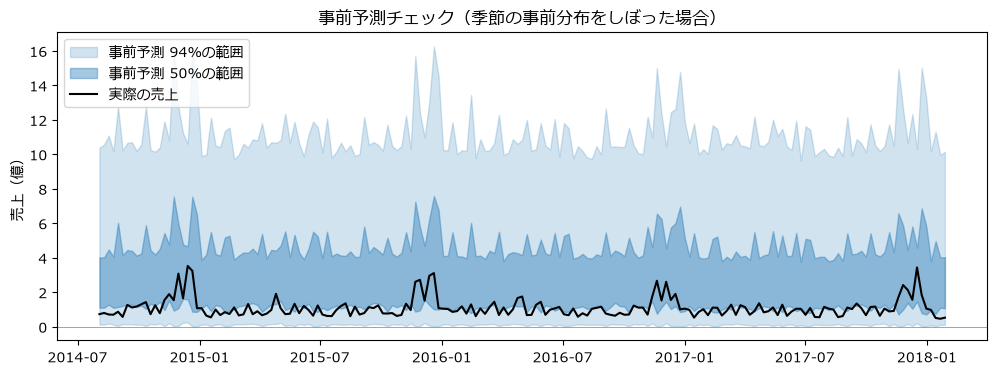

In [20]:
# 季節の係数：Laplace(0, 1) → Laplace(0, 0.1) に変更。ほかは同じ
config_tight = {**model_config, "gamma_fourier": Prior("Laplace", mu=0, b=0.1, dims="fourier_mode")}

mmm_tight = build_and_sample(config_tight)
plot_prior_predictive(mmm_tight, "事前予測チェック（季節の事前分布をしぼった場合）");

**読み方**

- 帯の上端が約24億から約11億に下がりました。それでも実際の売上はおおえています
- ところどころに、とがった山が見えるようになりました。これは祝日のある週です。5-1 で見たとおり、祝日の係数もややゆるいためです
  （モデルはまだ売上を学習していません。祝日フラグという入力データの形が映っているだけです）
- まだ実際の最大売上の約3倍あります。残りの幅の原因は、小課題1で調べます

**では、しぼったほうが正しいのか？**　一概には言えません。

- 季節の波は毎年くり返すので、3年半のデータがあれば、データから十分に決められます。その場合、ゆるい事前分布でも学習後の結果はほとんど変わりません
- 一方、データが1〜2年しかない場合は、ゆるい季節性が「広告の効果」まで吸い取ってしまうおそれがあります

本家のケーススタディ1は Laplace(0, 1) のまま学習に進んでいます。第4回も本家と同じ設定（`mmm`）で進めます。
※「3年半あればゆるくても問題になりにくい」は一般的な考え方に基づく私の解釈で、本家の説明ではありません。第4回以降の結果で確かめます。

### 5-3. 🧪 実験：事前分布を何も考えずに決めるとどうなるか

比較のために、`model_config` を渡さず、ライブラリの初期設定のままでモデルを作ります。
初期設定は ベース Normal(0, 2)、β HalfNormal(2)、誤差は下限なしの Normal です。

Sampling: [adstock_alpha, gamma_control, gamma_fourier, intercept_contribution, saturation_beta, saturation_lam, y, y_sigma]


94%の範囲の上端（週の平均）: 41.6 億
94%の範囲の下端（週の平均）: -19.5 億


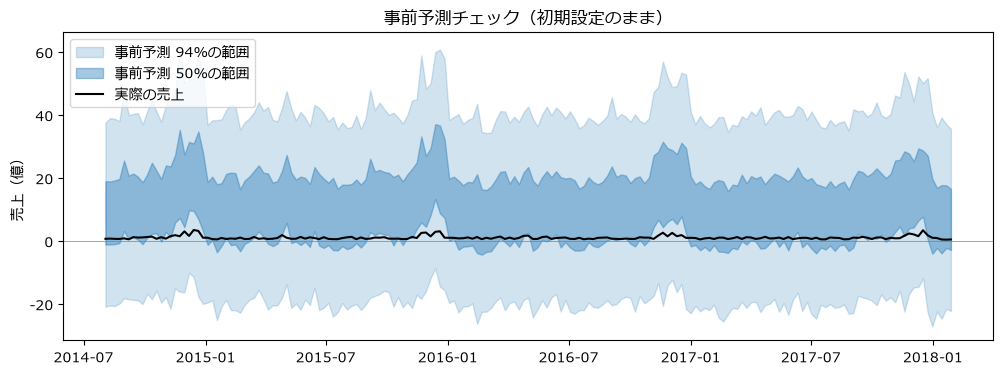

In [21]:
mmm_default = build_and_sample(None)
plot_prior_predictive(mmm_default, "事前予測チェック（初期設定のまま）");

**読み方**：縦軸の目盛りを、前の2つの図と見比べてください。

- 帯の下端は約マイナス20億。「売上がマイナス」という、ありえない世界まで想像しています
- 上端は約40億で、実際の最大売上の10倍以上です

このまま学習させても動くことは多いのですが、次の問題が起きやすくなります。

- 学習（MCMC）が不安定になり、時間がかかる
- データが少ないチャネルで、極端な推定値が出る

**3つの図のまとめ**

| 設定 | 帯の範囲（おおよそ） | 評価 |
|---|---|---|
| 初期設定のまま | −20億〜40億 | マイナスの売上を想像。広すぎる |
| ケーススタディ1 | 0〜24億 | マイナスなし。ベースと広告は妥当、季節がゆるい |
| 季節をしぼった場合 | 0〜11億 | 実際の売上に近づいた。まだ3倍ほど広い |

業務知識を使って事前分布を現実的な範囲にしぼるのが、MMM担当者の仕事です。
そして「どこをしぼり、どこをゆるく残したか」を説明できることが大切です。

## 6. 事前のチャネル貢献シェア

もう1つ確認します。事前分布の段階で、モデルは「広告による売上のうち、各チャネルが何%を占める」と想像しているでしょうか。
（本家と同じ設定の `mmm` を使います）

,費用シェア,事前の貢献シェア（平均）,下端（3%）,上端（97%）
DM,0.450,0.480,0.047,0.857
新聞,0.163,0.107,0.004,0.371
ディスプレイ,0.119,0.159,0.005,0.498
TV,0.100,0.079,0.002,0.287
ラジオ,0.068,0.093,0.003,0.330
ソーシャル,0.052,0.043,0.001,0.160
折込,0.048,0.038,0.001,0.146


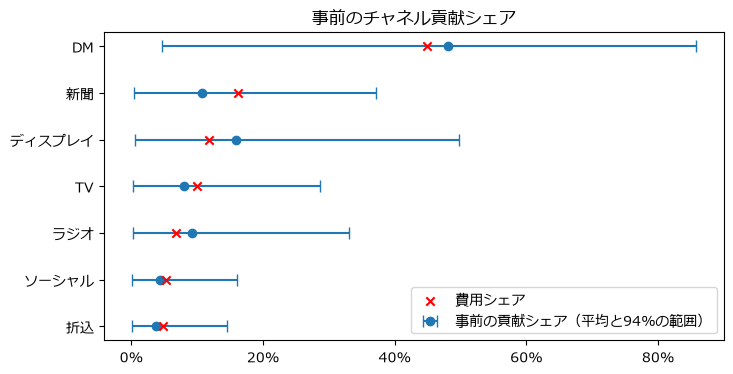

In [22]:
contrib = prior["channel_contribution"].sum(dim="date")          # チャネルごとの貢献の合計
share = contrib / contrib.sum(dim="channel")                      # 7チャネルの中での割合

share_mean = share.mean(dim=("chain", "draw")).to_series()
share_q = share.quantile([0.03, 0.97], dim=("chain", "draw"))
low = share_q.sel(quantile=0.03).to_series()
high = share_q.sel(quantile=0.97).to_series()

order = spend_share.sort_values().index
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    share_mean[order], order,
    xerr=[share_mean[order] - low[order], high[order] - share_mean[order]],
    fmt="o", capsize=4, label="事前の貢献シェア（平均と94%の範囲）",
)
ax.scatter(spend_share[order], order, marker="x", color="red", zorder=3, label="費用シェア")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("事前のチャネル貢献シェア")
ax.legend(loc="lower right");

pd.DataFrame({
    "費用シェア": spend_share,
    "事前の貢献シェア（平均）": share_mean,
    "下端（3%）": low,
    "上端（97%）": high,
}).loc[order[::-1]].round(3)

**読み方**

- 事前の貢献シェアの平均（青い丸）は、費用シェア（赤い×）に近い値です。β の広がりを費用シェアにしたので、当然こうなります
  （完全には一致しません。α・λ の事前分布や、週ごとの費用の出し方も影響するためです）
- 横棒（94%の範囲）はかなり長い。DM は約5%〜86% → 「DMが一番効く」と決めつけてはおらず、幅を持たせています
- **大事な点**：この図はまだデータを学習していません。「DMの貢献が大きい」のはデータの結論ではなく、私たちが置いた仮定です

第5回で、学習後の貢献シェア（事後分布）と見比べます。事前から大きく動いたチャネルが、「データが何かを語った」チャネルです。

## 7. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　下のセルは、5-2 の「季節をしぼった」設定です。誤差の大きさ `NOISE_SIGMA` を 1.0 から 0.2 に変えて実行してください。
帯はどう変わりますか。5-1 の結果（季節が幅の原因だった）と合わせて、何が言えますか。

Sampling: [adstock_alpha, gamma_control, gamma_fourier, intercept_contribution, saturation_beta, saturation_lam, y, y_sigma]


94%の範囲の上端（週の平均）: 6.1 億
94%の範囲の下端（週の平均）: 0.0 億


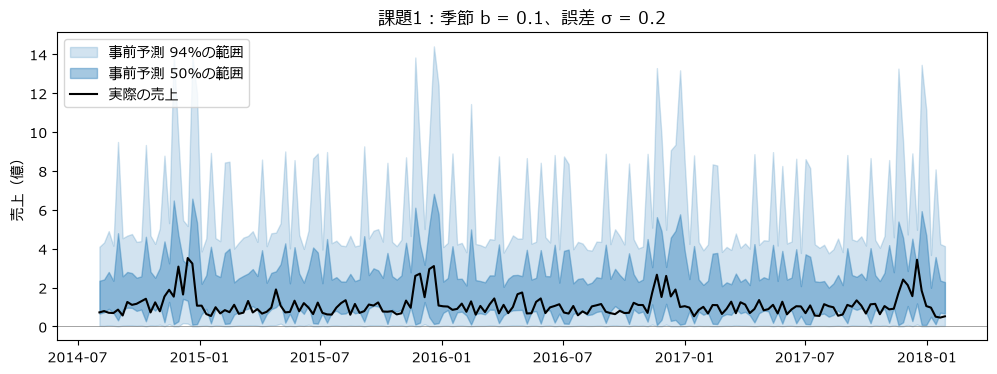

In [23]:
# 🧪 課題1：NOISE_SIGMA を 0.2 に変えて実行する（SEASON_B も自由に変えてみてください）
SEASON_B = 0.1
NOISE_SIGMA = 0.2

config_test = {
    **model_config,
    "gamma_fourier": Prior("Laplace", mu=0, b=SEASON_B, dims="fourier_mode"),
    "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=NOISE_SIGMA)),
}
mmm_test = build_and_sample(config_test)
plot_prior_predictive(mmm_test, f"課題1：季節 b = {SEASON_B}、誤差 σ = {NOISE_SIGMA}");

<details>
<summary>答えを見る</summary>

帯の上端が約11億から約6億に下がります。誤差 σ も帯を広げていた、ということです。

ただし順番が大事です。季節がゆるいまま（b = 1）誤差だけを 0.2 にしても、上端は約24億から約23億にしか下がりません（`SEASON_B = 1.0` にして確かめられます）。
いちばん大きな原因が残っているうちは、ほかをしぼっても効果が見えません。**大きい原因から順につぶす**のが、事前分布の調整のコツです。

</details>

**課題2**　ある会社は、効果を確かめないまま「昔からの付き合い」で新聞に予算の半分を使っています。
この会社に、費用シェアに基づく β の事前分布をそのまま使うと、何が起きそうですか。

<details>
<summary>答えを見る</summary>

新聞の β の事前分布が広くなり、「新聞は大きな効果がありうる」という前提からスタートします。
データが十分にあれば学習で修正されますが、データが少ない・広告費の変動が小さい場合は事前分布の影響が残り、新聞の貢献が実際より大きく出るおそれがあります。
対策の例：全チャネルの σ を同じにする、過去の効果検証の結果を事前分布に入れる、事前分布を変えても結論が変わらないかを確かめる（感度分析）。

</details>

**課題3**　6章の図で、DMの事前の貢献シェアは平均で約48%でした。この数字を「DMは広告による売上の約半分を生んでいます」と報告してよいでしょうか。

<details>
<summary>答えを見る</summary>

いけません。これは学習前の数字で、費用シェアをもとに私たちが置いた仮定を映しただけです。94%の範囲も約5%〜86%と、ほとんど何も言えていません。
報告に使えるのは、データを学習した後の事後分布（第5回）です。

</details>

## 8. まとめ

- MMMは「ベース ＋ 広告の貢献 ＋ 祝日 ＋ 季節 ＋ 誤差」の足し算。推定するパラメータは55個、データは183週
- データだけでは決めきれないので、**事前分布**で「ありそうな範囲」を先に与える
- ケーススタディ1の工夫：β の広がりを**費用シェア**にする（費用の少ないチャネルの推定が暴れるのを防ぐ）
- PyMC-Marketing は売上と広告費を**最大値で自動スケーリング**する。事前分布の数字は 0〜1 にそろえた世界での値
- **事前予測チェック**：学習前に、モデルが想像する売上の範囲を図で確かめる
  - ケーススタディ1の設定は、ベースと広告は妥当、季節性はゆるい
  - 帯が広いときは、部品ごとに分けて原因を探す
- 事前の貢献シェアは「仮定」であって「結論」ではない

**次回（第4回）**：いよいよ学習（MCMC）を実行し、結果が信頼できるかを診断します。